# 04 · Baselines y criterios de aceptación (Fase 6)
Antes de modelar se define qué significa "funcionar".

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]

In [2]:
display(tabla[tabla.Modelo.str.startswith("Base")])

,Modelo,AUC CV (media),AUC CV (desv.),AUC prueba,Exactitud balanceada prueba,F1 prueba,Brier prueba
0,Base: siempre la clase mayoritaria,0.500,0.000,0.500,0.500,0.682,0.250
1,Base: sólo índice de origen,0.531,0.022,0.556,0.533,0.642,0.248


## Criterios de aceptación
| Métrica | Por qué | Umbral mínimo |
|---|---|---|
| **AUC** | Capacidad de ordenar riesgo; no depende del umbral | Superar a los dos baselines por ≥ 0.05 |
| Exactitud balanceada | Las clases están casi 50/50, pero se cuida igual | > 0.60 |
| Brier | Calibración de probabilidades (menor es mejor) | < 0.25 (baseline) |
| Desempeño por subgrupo | Que no falle en grupos vulnerables | AUC > 0.6 en grupos con n ≥ 100 |

**Lectura del baseline:** dentro del 20% más pobre, el índice de origen por sí solo casi no distingue quién sale (AUC ≈ 0.53–0.56). Las diferencias **dentro** del fondo de la distribución dependen de otras circunstancias.

## Métricas completas, incluida la predicción estratificada

In [3]:
from src.models import diagnostics as D
modelos["Base: estratificada"] = D.stratified_baseline(tr, te, T.NUM, T.CAT)
fm, cms = D.full_metrics(modelos, te, T.NUM, T.CAT); fm.to_csv(TABLES / "metricas_completas.csv", index=False)
display(fm); display(Markdown("**Matriz de confusión — regresión logística**")); display(cms["Regresión logística"])

,Modelo,AUC,PR-AUC,Log loss,Precisión (sigue Q1),Recall (sigue Q1),Precisión (sale),Recall (sale),Macro F1
0,Base: siempre la clase mayoritaria,0.500,0.518,0.693,0.518,1.000,0.000,0.000,0.341
1,Base: sólo índice de origen,0.556,0.580,0.688,0.539,0.794,0.551,0.271,0.503
2,Regresión logística,0.716,0.720,0.618,0.681,0.686,0.660,0.655,0.671
3,Árbol de decisión,0.681,0.653,0.645,0.663,0.682,0.648,0.628,0.655
4,Random forest,0.722,0.725,0.629,0.653,0.708,0.655,0.597,0.652
5,Gradient boosting,0.721,0.720,0.615,0.671,0.671,0.647,0.647,0.659
6,Base: estratificada,0.501,0.518,6.895,0.519,0.495,0.483,0.508,0.501


**Matriz de confusión — regresión logística**

,Pred: sale,Pred: sigue
Real: sale,169,89
Real: sigue,87,190


## Calibración
¿Cuando el modelo dice 60%, de verdad siguen en Q1 alrededor del 60%?

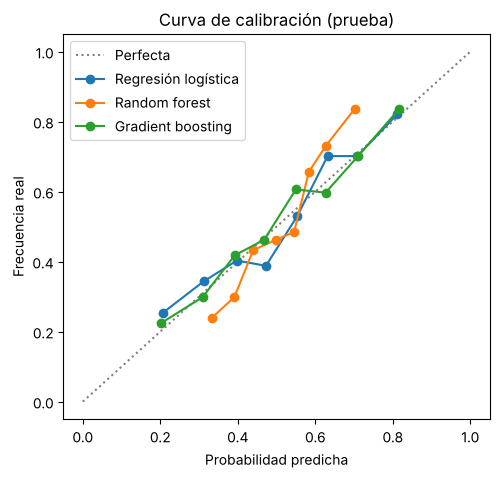

In [4]:
import matplotlib.pyplot as plt
cal = D.calibration_table({k: modelos[k] for k in ["Regresión logística", "Random forest", "Gradient boosting"]}, te, T.NUM, T.CAT)
fig, ax = plt.subplots(figsize=(5.5, 5)); ax.plot([0, 1], [0, 1], ":", color="gray", label="Perfecta")
for k, c in cal.items(): ax.plot(c["Prob. predicha"], c["Frecuencia real"], "o-", label=k)
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Frecuencia real"); ax.set_title("Curva de calibración (prueba)"); ax.legend()
fig.savefig(FIGURES / "10_calibracion.png", bbox_inches="tight", dpi=200); plt.show()

## Desbalance de clases
Las clases están casi balanceadas (52% sigue / 48% sale). Aun así se compara con `class_weight='balanced'`.

In [5]:
cw = D.class_weight_check(tr, T.NUM, T.CAT); cw.to_csv(TABLES / "class_weight.csv"); display(cw)

,AUC CV,Exactitud balanceada CV
Sin pesos,0.696,0.642
class_weight='balanced',0.696,0.642


**Lectura:** los pesos por clase no cambian nada, porque el desbalance es mínimo. No hace falta oversampling. La predicción estratificada (al azar, respetando las proporciones) da AUC = 0.50 y un log loss muy alto: es el piso.

**Estado de la fase:** PROPUESTA — falta la revisión humana (regla de avance del roadmap: APROBADA / APROBADA CON CAMBIOS / REABRIR / BLOQUEADA).